In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [102]:
import os

LOCAL_PATH = "data/USA_Housing.csv"
DRIVE_PATH = "/content/drive/My Drive/AI projects/USA Housing Price(linear regression)/USA_Housing.csv"
DATA_URL   = "https://raw.githubusercontent.com/<REPO>/main/data/USA_Housing.csv"

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

if os.path.exists(LOCAL_PATH):
    print("Loading from local file")
    df = pd.read_csv(LOCAL_PATH)
elif os.path.exists(DRIVE_PATH):
    print("Loading from Google Drive")
    df = pd.read_csv(DRIVE_PATH)
else:
    print("Loading from GitHub")
    df = pd.read_csv(DATA_URL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading from Google Drive


In [103]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [105]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


# EDA

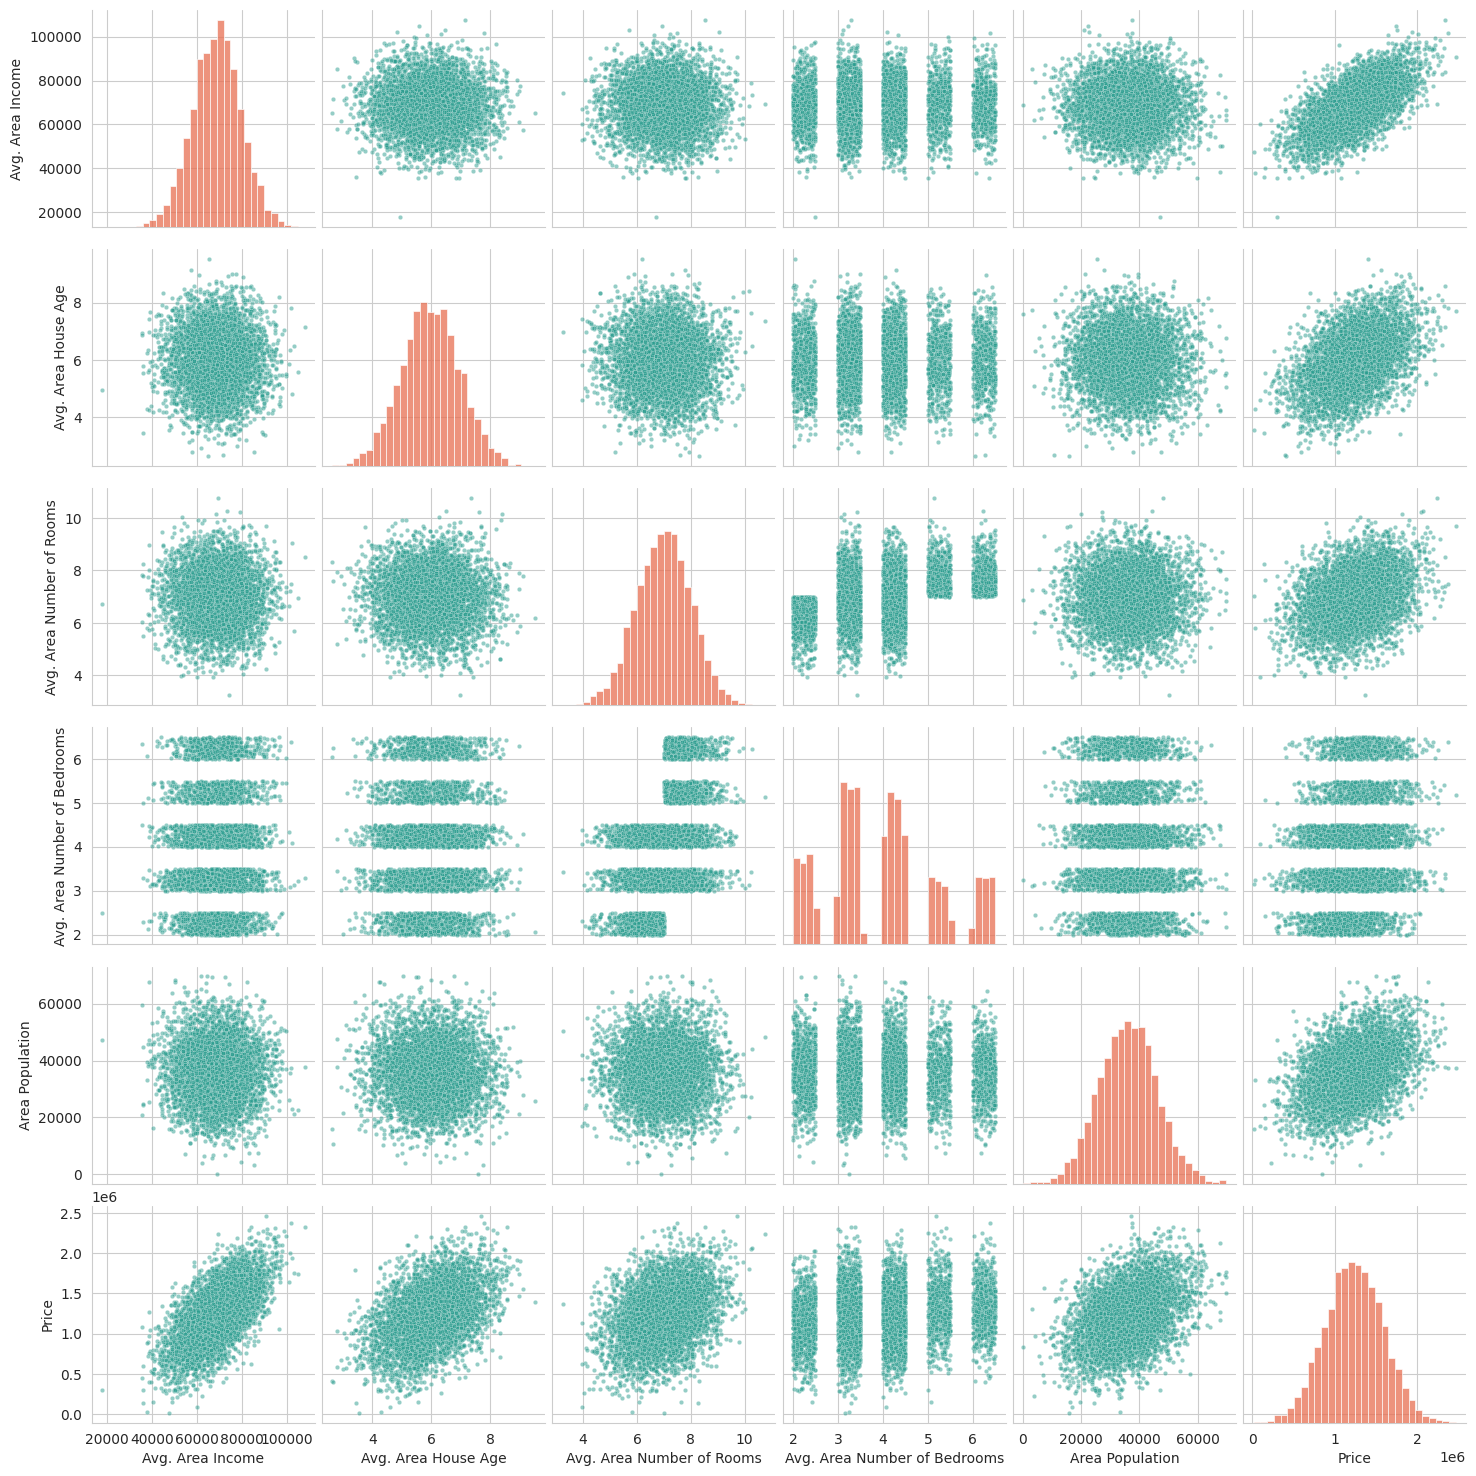

In [106]:
sns.pairplot(
    df,
    diag_kws={"color": "#e76f51", "edgecolor": "white", "bins": 30},
    plot_kws={"color": "#2a9d8f", "s": 10, "alpha": 0.5}
)

<Axes: xlabel='Price', ylabel='Count'>

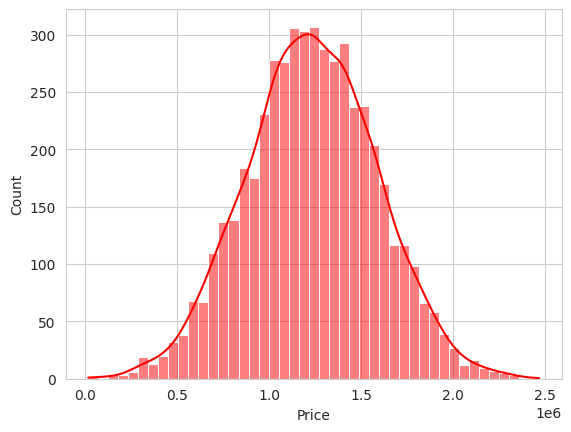

In [107]:
sns.histplot(df['Price'], color="red", kde=True)

<Axes: >

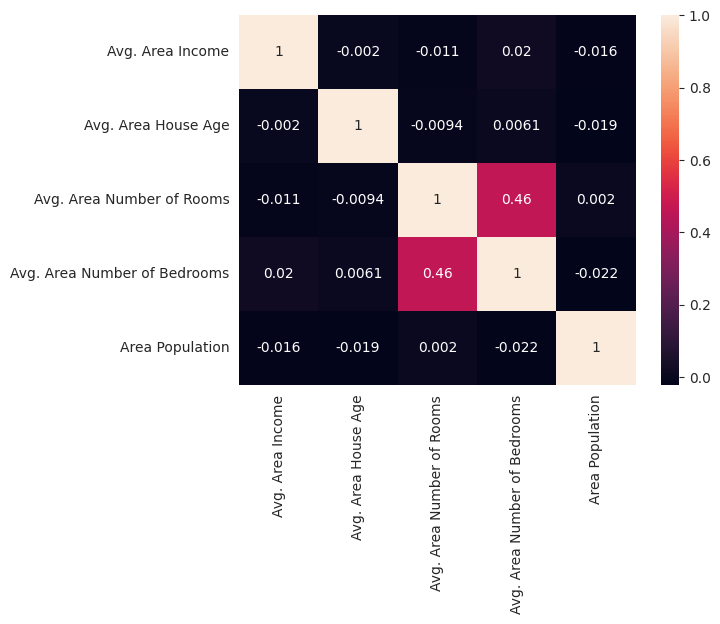

In [108]:
sns.heatmap(df[df.columns[:5]].corr(),annot= True)

In [109]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [110]:
X=df[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms','Avg. Area Number of Bedrooms', 'Area Population']]
Y=df['Price']

In [111]:
from sklearn.model_selection import train_test_split

In [112]:
X_train,X_test,y_train,y_test = train_test_split(X,Y, test_size = 0.3, random_state= 101)

In [113]:
from sklearn.linear_model import LinearRegression

In [114]:
lm = LinearRegression()

In [115]:
lm.fit(X_train,y_train)

LinearRegression()

In [116]:
y_predict = lm.predict(X_test)

In [117]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error, r2_score
print("MAE:",mean_absolute_error(y_test,y_predict))
print("MSE:",mean_squared_error(y_test,y_predict))
print("RMSE:",root_mean_squared_error(y_test,y_predict))
print("R2:",r2_score(y_test,y_predict))


MAE: 81257.55795855941
MSE: 10169125565.897606
RMSE: 100842.08231635048
R2: 0.9185060945363622


1500 1500
Mean % error:   7.63%
Median % error: 5.73%


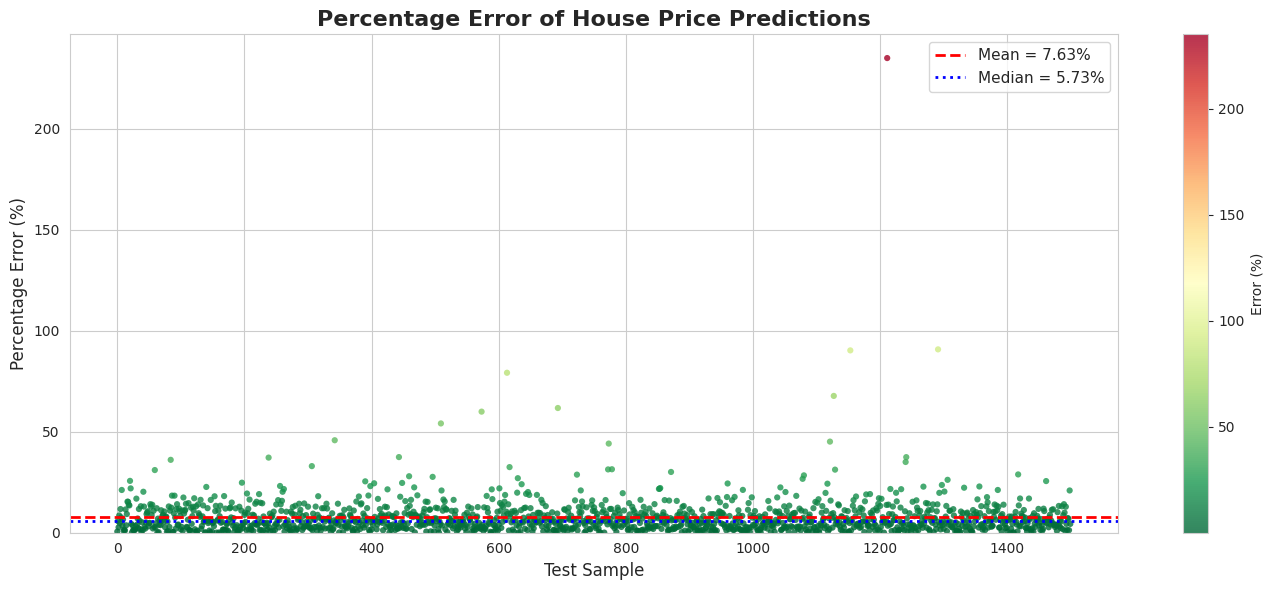

In [118]:
percentage_error = (np.abs(y_predict - y_test.values) / y_test.values) * 100

mean_err   = percentage_error.mean()
median_err = np.median(percentage_error)

print(len(percentage_error), len(y_test))
print(f"Mean % error:   {mean_err:.2f}%")
print(f"Median % error: {median_err:.2f}%")

plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")


sc = plt.scatter(range(len(percentage_error)), percentage_error,
                 c=percentage_error, cmap="RdYlGn_r",
                 s=20, alpha=0.8, edgecolors="none")
plt.colorbar(sc, label="Error (%)")


plt.axhline(mean_err,   color="red",  ls="--", lw=2, label=f"Mean = {mean_err:.2f}%")
plt.axhline(median_err, color="blue", ls=":",  lw=2, label=f"Median = {median_err:.2f}%")



plt.title("Percentage Error of House Price Predictions", fontsize=16, weight="bold")
plt.xlabel("Test Sample", fontsize=12)
plt.ylabel("Percentage Error (%)", fontsize=12)
plt.ylim(bottom=0)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()